<font face="Times New Roman" size=5>
<div dir=rtl align="center">
<font face="Times New Roman" size=5>
In The Name of God
</font>
<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Electrical Engineering Department
</font>
<br>
<font color="#008080" size=6>
Probability and Statistics
</font>
<hr/>
<font color="#800080" size=5>
Assignment 2
<br>
</font>
<font size=5>
Instructor: Dr. Yassaee
<br>
</font>
<font size=4>
Fall 2025
<br>
</font>
<font face="Times New Roman" size=4>
Deadline: 12 Dey 1404
</font>
<hr>
<br>
</font>
<font face="Times New Roman" size=4 align=center>
Feel free to ask your questions in Telegram : @Ali99os
</font>
<br>
<hr>
</div></font>

# Question 1

### Detecting Nonlinear Dependence in a Continuous Joint Distribution

Let $X$ be a continuous random variable uniformly distributed on $[-1,1]$, and let  
$$
Y = X^{2} + \varepsilon,
$$
where $\varepsilon \sim N(0,\sigma^{2})$ is independent of $X$.

The goal of this assignment is to explore the difference between linear correlation and true statistical dependence, using both classical rank-based measures and modern nonlinear dependence measures.


#### A)  Analytical Component: Covariance and Correlation

1. Compute $E[X]$, $E[X^{2}]$, $E[X^{3}]$, and show that  
   $$
   \operatorname{Cov}(X, X^{2}) = 0.
   $$

2. Using independence and $E[\varepsilon]=0$, prove that  
   $$
   \operatorname{Cov}(X, Y) = 0.
   $$

3. Conclude that the Pearson correlation between $X$ and $Y$ is zero, even though a nonlinear functional relationship exists.


1.Cov(X,X^2)=E[(X-E[X])*(X^2-E[X^2])]=E[X^3-X*E[X^2]-X^2*E[X]+E[X]*E[X^2]]=E[X^3]-E[X^2]*E[X]=INT(X^3*1/2*dx)\(from -1 to 1)-0=0;
2.Cov(X,Y)=E[X*(X^2+e)]-E[X]*(E[X^2]+E[e])=E[X^3]+E[X*e]-E[X]*E[X^2]=E[X]*E[e]=0;

3. همان طور که دیده می شود، با توجه به رابطه مستقیم همبتسگی پیرسون با کواریانس، همبستگی بین X و Y صفر است. چون این همبستگی خطی را بررسی می کند و نه لزوما هر همبستگی را.


#### B) Simulation and Classical Dependence Measures

Simulate $n = 1000$ samples of $X \sim U(-1,1)$ and $\varepsilon \sim N(0, 0.05^{2})$, and construct $Y = X^{2} + \varepsilon$.

Perform the following tasks:

##### B.1 Visualizations
- Create a scatter plot of $(X, Y)$.  
- Plot histograms of $X$ and $Y$.

##### B.2 Compute the following dependence measures

##### (a) Pearson Correlation
$$
\rho_{X,Y} =
\frac{\operatorname{Cov}(X,Y)}{\sqrt{\operatorname{Var}(X)\operatorname{Var}(Y)}}
$$
Measures *linear* dependence.

##### (b) Spearman Rank Correlation
Spearman’s rho is the Pearson correlation applied to ranked data:
$$
\rho_{S} = \rho(\operatorname{rank}(X),\, \operatorname{rank}(Y)).
$$
For continuous variables:
$$
\rho_{S} = 12\,E[F_X(X)\,F_Y(Y)] - 3.
$$
Measures *monotonic* dependence.

##### (c) Kendall’s Tau
Defined using concordant and discordant pairs:
$$
\tau =
P\big((X_1 - X_2)(Y_1 - Y_2) > 0\big)
-
P\big((X_1 - X_2)(Y_1 - Y_2) < 0\big).
$$
Measures *pairwise ordering* dependence.

Interpret all results and discuss how they differ from the theoretical Pearson result.



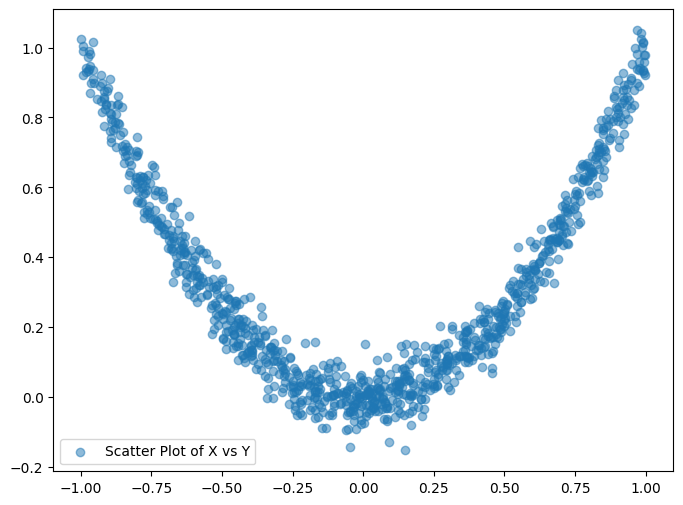

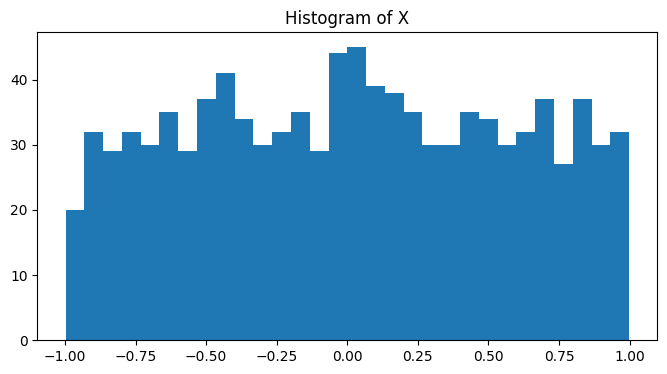

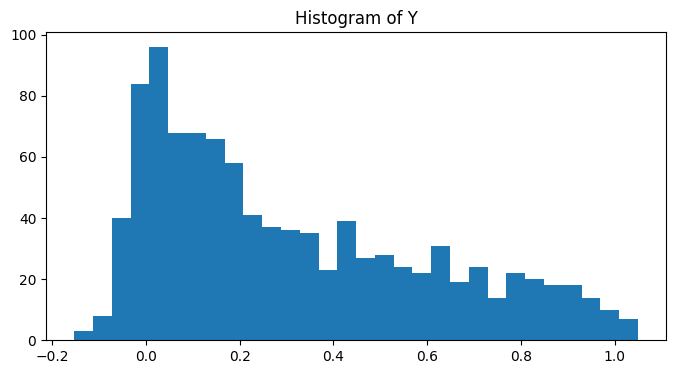

Pearson correlation coefficient: PearsonRResult(statistic=np.float64(0.053078633816992224), pvalue=np.float64(0.09342968590228183))
Spearman correlation coefficient: SignificanceResult(statistic=np.float64(0.040072780072780076), pvalue=np.float64(0.20546431550784475))
kendall-tau correlation coefficient: SignificanceResult(statistic=np.float64(0.03275675675675676), pvalue=np.float64(0.12088378832725567))


In [6]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.core.pylabtools import figsize
from h11 import NEED_DATA
from scipy.stats import pearsonr, spearmanr,kendalltau
plt.figure(figsize=(8,6))
X=np.random.uniform(-1,1,1000)
e=np.random.normal(loc=0.0,scale=0.05,size=1000)
Y=e+X**2
plt.scatter(X,Y,alpha=0.5,label='Scatter Plot of X vs Y')
plt.legend()
plt.show()

plt.figure(figsize(8,4))
plt.hist(X,bins=30)
plt.title('Histogram of X')
plt.show()

plt.figure(figsize(8,4))
plt.hist(Y,bins=30)
plt.title('Histogram of Y')
plt.show()

pear=pearsonr(X,Y)
spearman=spearmanr(X,Y)
kendalltau=kendalltau(X,Y)

print("Pearson correlation coefficient:", pear)
print("Spearman correlation coefficient:", spearman)
print("kendall-tau correlation coefficient:", kendalltau)

#### C) Nonlinear Dependence Measures

Compute at least two of the following nonlinear measures and include the mathematical definitions.

##### (a) Distance Correlation

Let $a_{ij} = \|X_i - X_j\|$ and $b_{ij} = \|Y_i - Y_j\|$.  
Define centered distance matrices:
$$
A_{ij} = a_{ij} - \bar{a}_{i\cdot} - \bar{a}_{\cdot j} + \bar{a}_{\cdot\cdot},
\quad
B_{ij} = b_{ij} - \bar{b}_{i\cdot} - \bar{b}_{\cdot j} + \bar{b}_{\cdot\cdot}.
$$

Empirical distance covariance:
$$
\operatorname{dCov}^{2}(X,Y)
= \frac{1}{n^{2}} \sum_{i,j} A_{ij} B_{ij}.
$$

Distance correlation:
$$
\operatorname{dCor}(X,Y)
=
\frac{\operatorname{dCov}(X,Y)}
{\sqrt{\operatorname{dCov}(X,X)\,\operatorname{dCov}(Y,Y)}}.
$$

Distance correlation equals 0 if and only if the variables are independent.



##### (b) HSIC (Hilbert–Schmidt Independence Criterion)

Given kernels $k(x,x')$ and $l(y,y')$, define Gram matrices:
$$
K_{ij} = k(X_i, X_j), \qquad
L_{ij} = l(Y_i, Y_j).
$$

Let  
$$
H = I_n - \frac{1}{n}\mathbf{1}\mathbf{1}^{\top}.
$$

Empirical HSIC:
$$
\operatorname{HSIC}(X,Y)
=
\frac{1}{n^{2}} \operatorname{Tr}(KHLH).
$$

With universal kernels (e.g., Gaussian RBF),  
$$
\operatorname{HSIC}(X,Y) = 0 \quad \text{iff} \quad X \text{ and } Y \text{ are independent}.
$$


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import math
n=1000
X=np.random.uniform(-1,1,n)
e=np.random.normal(loc=0.0,scale=0.05,size=n)
Y=e+X**2
x=np.asarray(X).ravel()
y=np.asarray(Y).ravel()
a_row=np.zeros(n,dtype=float)
b_row=np.zeros(n,dtype=float)
a_total=0.0
b_total=0.0
sum_AB=0.0
sum_BB=0.0
sum_AA=0.0
for i in range(n):
    for j in range(n):
        aij=abs(x[i]-x[j])
        bij=abs(y[i]-y[j])
        a_row[i]+=aij
        b_row[i]+=bij
        a_total+=aij
        b_total+=bij

    a_row[i]/=n
    b_row[i]/=n
a_total/=n*n
b_total/=n*n

for i in range(n):
    for j in range(n):
        aij=abs(x[i]-x[j])
        bij=abs(y[i]-y[j])
        Aij=aij-a_row[i]-a_row[j]+a_total
        Bij=bij-b_row[i]-b_row[j]+b_total
        sum_AB+=Aij*Bij
        sum_BB+=Bij*Bij
        sum_AA+=Aij*Aij
dcov_AA2=sum_AA/(n*n)
dcov_BB2=sum_BB/(n*n)
dcov_AB2=sum_AB/(n*n)

dcor_AB=math.sqrt(dcov_AB2)/math.sqrt(math.sqrt(dcov_AA2*dcov_BB2))

print("dcor_AB:",dcor_AB)


def rbf_gram(x,sigma):
    x=np.asarray(x).reshape(-1,1)
    d2=(x-x.T)**2
    K=np.exp(-d2/(2*sigma**2))
    return K

def center_gram(K):
    m=K.shape[0]
    H=np.eye(m)-np.ones((m,m))/m
    return H@K@H

def hsic_rbf(x,y,sigma_x,sigma_y):
    K=rbf_gram(x,sigma_x)
    H=rbf_gram(y,sigma_y)
    Kc=center_gram(K)
    Hc=center_gram(H)
    hsic=np.sum(Kc*Hc)/n**2
    return hsic
def median_sigma(x):
    x=np.asarray(x).ravel()
    diff=np.abs(x[:,None]-x[None,:])
    return np.median(diff[diff>0])
sx=median_sigma(x)
sy=median_sigma(y)
hsic=hsic_rbf(x,y,sx,sy)
print("hsic is:",hsic)

dcor_AB: 0.4952126688639906
hsic is: 0.032885377409269986


#### D) Sensitivity Analysis

Repeat the computations for:

- $\sigma \in \{0.01, 0.05, 0.1, 0.3\}$  
- $n \in \{100, 500, 1000, 5000\}$

For each pair:

1. Compute Pearson correlation.  
2. Compute at least one nonlinear measure (distance correlation or HSIC).  
3. Summarize results in a table or heatmap.  
4. Briefly describe how noise level and sample size affect the detectability of dependence.


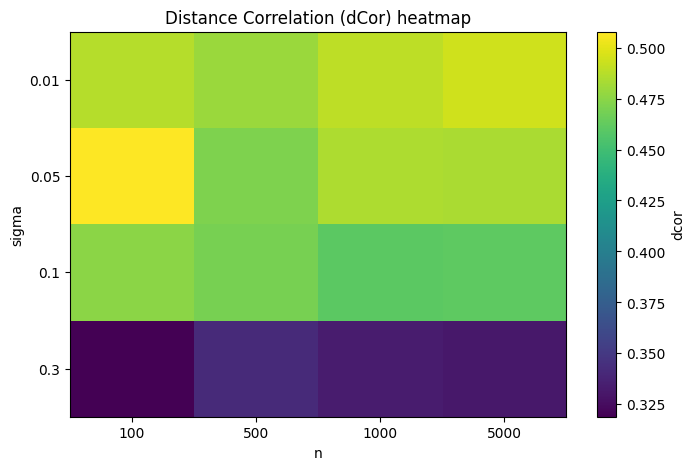

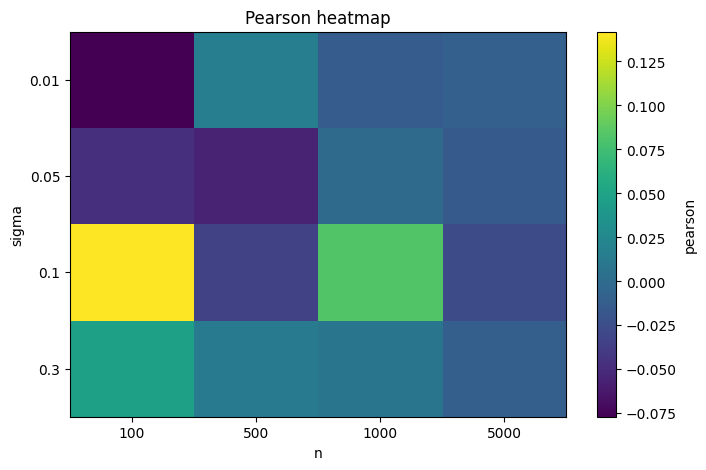

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr,kendalltau
import math
import pandas as pd
def dcor(X,Y):
    n=len(X)
    x=np.asarray(X).ravel()
    y=np.asarray(Y).ravel()
    a_row=np.zeros(n,dtype=float)
    b_row=np.zeros(n,dtype=float)
    a_total=0.0
    b_total=0.0
    sum_AB=0.0
    sum_BB=0.0
    sum_AA=0.0
    for i in range(n):
        for j in range(n):
            aij=abs(x[i]-x[j])
            bij=abs(y[i]-y[j])
            a_row[i]+=aij
            b_row[i]+=bij
            a_total+=aij
            b_total+=bij

        a_row[i]/=n
        b_row[i]/=n
    a_total/=n*n
    b_total/=n*n

    for i in range(n):
        for j in range(n):
            aij=abs(x[i]-x[j])
            bij=abs(y[i]-y[j])
            Aij=aij-a_row[i]-a_row[j]+a_total
            Bij=bij-b_row[i]-b_row[j]+b_total
            sum_AB+=Aij*Bij
            sum_BB+=Bij*Bij
            sum_AA+=Aij*Aij
    dcov_AA2=sum_AA/(n*n)
    dcov_BB2=sum_BB/(n*n)
    dcov_AB2=sum_AB/(n*n)

    dcor_AB=math.sqrt(dcov_AB2)/math.sqrt(math.sqrt(dcov_AA2*dcov_BB2))
    return dcor_AB

sigmas=[0.01,0.05,0.1,0.3]
ns=[100,500,1000,5000]
rows=[]
for i in range(len(sigmas)):
    for j in range(len(sigmas)):
        X=np.random.uniform(-1,1,ns[i])
        e=np.random.normal(loc=0.0,scale=sigmas[j],size=ns[i])
        Y=e+X**2
        pear=pearsonr(X,Y).statistic
        dc=dcor(X,Y)
        rows.append({"sigma":sigmas[j],"n":ns[i],"pearson":pear,"dcor":dc})
df=pd.DataFrame(rows)
dcor_table=df.pivot(index="sigma",columns="n",values="dcor")
pearson_table=df.pivot(index="sigma",columns="n",values="pearson")
plt.figure(figsize=(8,5))
plt.imshow(dcor_table.values,aspect='auto')
plt.colorbar(label='dcor')
plt.xticks(range(len(dcor_table.columns)),dcor_table.columns)
plt.yticks(range(len(dcor_table.index)),dcor_table.index)
plt.xlabel('n')
plt.ylabel('sigma')
plt.title("Distance Correlation (dCor) heatmap")
plt.show()
plt.figure(figsize=(8,5))
plt.imshow(pearson_table.values,aspect='auto')
plt.colorbar(label='pearson')
plt.xticks(range(len(pearson_table.columns)),pearson_table.columns)
plt.yticks(range(len(pearson_table.index)),pearson_table.index)
plt.xlabel('n')
plt.ylabel('sigma')
plt.title("Pearson heatmap")
plt.show()
#همان طور که دیده می شود، با افزایش واریانس، چون نویز بیشتر می شود، دیستنس کلبریشن ما دقتش را برای سنجش وابستگی از دست می دهد. اما با افزایش n، نتیجه پایدار تر و منطقی تر می شود

# Question 2


### **Part 1: Plotting the Convergence of the Average of Random Variables**

**Question**: Using the Law of Large Numbers, generate a plot that shows the convergence of the average of random variables to their expected value. For this task:

* Use Poisson random variables with a rate (lambda) of 4.5.
* Sample 100,000 values and plot the average for the first `n` samples, for `n = 1` to 100,000.
* Include the expected value of the Poisson distribution (4.5) as a reference line in the plot.

Provide the code to generate this plot. Remember to replace the specific part of the code with `#to do` where appropriate.


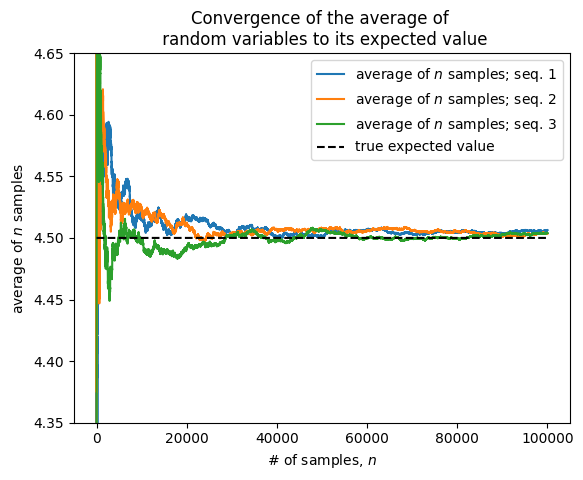

In [7]:
import numpy as np
import matplotlib.pyplot as plt
lambda_val=4.5
expected_val=4.5
N=100000
N_samples=np.arange(1,N+1)
for k in range(3):
    samples =np.random.poisson(lam=lambda_val,size=N)
    partial_average = [samples[:i].mean() for i in N_samples]
    plt.plot(N_samples, partial_average, lw=1.5, label=f"average of $n$ samples; seq. {k+1}")

plt.plot(N_samples, expected_val * np.ones_like(partial_average),
         ls="--", label="true expected value", c="k")

plt.ylim(4.35, 4.65)
plt.title("Convergence of the average of \n random variables to its expected value")
plt.ylabel("average of $n$ samples")
plt.xlabel("# of samples, $n$")
plt.legend()
plt.show()



### **Part 2: Plotting the Expected Distance from True Value**

**Question**: Using the Law of Large Numbers, compute and plot the expected squared-distance between the sample mean and the true expected value as the sample size increases. Approximate the variance for various sample sizes.

* Use a Poisson distribution with a rate (lambda) of 4.5.
* Plot the expected distance as a function of `N` (sample size).

Provide the code to perform the computation and generate the plot.


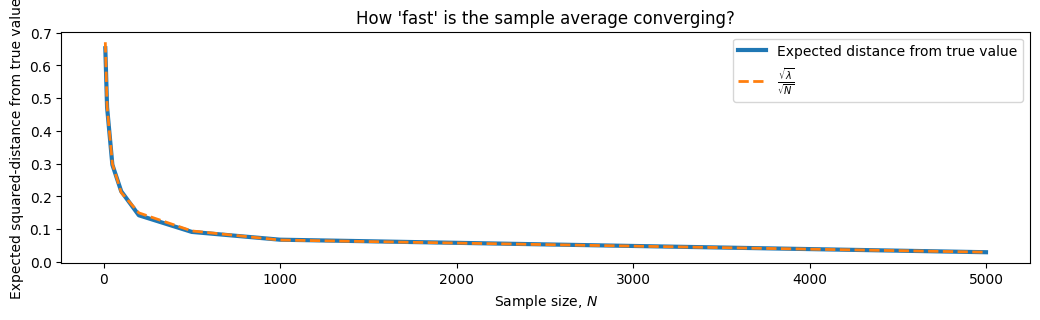

In [10]:
import numpy as np
import matplotlib.pyplot as plt
lambda_val=4.5
N_array = np.array([10, 20, 50, 100, 200, 500, 1000, 5000])
D_N_results = np.zeros(len(N_array))
def D_N(n):
    distances = []
    for i in range(500):
        Xn=np.random.poisson(lam=lambda_val,size=n)
        mean_xn=Xn.mean()
        distances.append((4.5-mean_xn)**2)
    return np.sqrt(np.mean(distances))

for i, n in enumerate(N_array):
    D_N_results[i] = D_N(n)

plt.figure(figsize=(12.5, 3))
plt.plot(N_array, D_N_results, lw=3, label="Expected distance from true value")
plt.plot(N_array, np.sqrt(lambda_val)/np.sqrt(N_array), lw=2, ls="--", label=r"$\frac{\sqrt{\lambda}}{\sqrt{N}}$")
plt.xlabel("Sample size, $N$")
plt.ylabel("Expected squared-distance from true value")
plt.legend()
plt.title("How 'fast' is the sample average converging?")
plt.show()



### **Part 3: Estimating Probability Using the Law of Large Numbers**

**Question**: Estimate the probability that a sample from an Exponential distribution with rate 0.5 is greater than 5. Use 10,000 samples for the estimation.

Provide the code to compute the probability.


In [14]:
import numpy as np

N=10000
X=np.random.exponential(scale=2.0,size=N)
probability_estimate=np.mean((X>5))
print("Estimated Probability (P(X > 5)):", probability_estimate)


Estimated Probability (P(X > 5)): 0.0828



### **Part 4: Theoretical Question on Convergence Rates**

**Question**: Based on the previous plots and the Law of Large Numbers, analyze the convergence rate of the sample mean to the true expected value. Specifically, discuss:

* How does the expected distance decrease as the sample size increases?
* Based on the convergence plots, estimate the rate at which the distance decreases and compare it to the theoretical rate of convergence $\frac{\sqrt{\lambda}}{\sqrt{N}}$.
* Report any trends observed, and comment on how much additional improvement in accuracy is gained by increasing the sample size.


1
نوسان ها در n های کم به نسبت زیاد است اما با رشد n، شدیدا نسبت به میانگین واقعی دمپ می شوند.
2
همان طور که در شکل دیده می شود شبیه نمودار x به توان منفی یک دوم است.
3
بله سازگار است. چون این عبارت انحراف معیار میانگین xn هاست
4
واضحا و منطبقا با قانون اعداد بزرگ، با افزایش تعداد، خطا کمتر می شود

# Question 3

In this question, you will use simulations to verify the Central Limit Theorem (CLT) through repeated dice-rolling experiments, both for fair and unfair dice.

## **Background**

The **Central Limit Theorem** says:

> When many independent, identically distributed random variables are added together, their normalized sum tends toward a **normal distribution**, regardless of the original distribution.

The distribution of a *single die roll* is very far from a normal distribution, but the **sum of many** rolls will become increasingly bell-shaped.

Let:

* Each die roll be a random variable
* Mean of a single roll: ( $\mu$ )
* Variance of a single roll: ( $\sigma^2$ )

Then the **sum of (n) rolls** has:

* Mean:
  $$
  \mu_{\text{sum}} = n\mu
  $$
* Variance:
  $$
  \sigma_{\text{sum}}^2 = n\sigma^2
  $$

You will confirm these predictions experimentally.

**Complete the `TODO` parts.**




## Imports and Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

## Fair Die Roll Function

Write a function that returns uniformly integers from 1 to 6

In [8]:
def roll_fair_die(size):
    # TODO: complete the function
    return np.random.randint(1, 7, size)

## Unfair Die Roll Function

Write a function that returns random results from an unfair die. You may choose any non-uniform probabilities.

In [18]:
def roll_unfair_die(size):
    f=np.array([1,2,3,4,5,6])
    p=np.array([0.10, 0.20, 0.05, 0.25, 0.30, 0.10])
    return np.random.choice(f,size=size, p=p)

## Function to Simulate Sums

This runs many trials, each consisting of `n_rolls` dice rolls.




In [19]:
def simulate_sums(roll_fn, n_rolls, n_trials):
    sum=np.zeros(n_trials,dtype=float)
    for i in range(n_trials):
        rolls=roll_fn(size=n_rolls)
        sum[i]=np.sum(rolls)
    return  sum

## Plotting Histograms With Normal Curve for CLT Comparison

In [20]:
def plot_with_normal(data, n_rolls, mu, sigma, title):
    plt.figure(figsize=(8,5))
    plt.hist(data,bins=30,density=True,alpha=0.5)
    xs=np.linspace(data.min(),data.max(),400)
    plt.plot(xs,norm.pdf(xs,loc=n_rolls*mu,scale=np.sqrt(n_rolls)*sigma),lw=2)
    plt.title(title)
    plt.xlabel("sum")
    plt.ylabel("density")
    plt.show()

## Theoretical Mean and Variance for Fair and Unfair Dice

Here you calculate the theoritical values that CLT predicts for the distributions of means of samples.

In [21]:
# Fair die theoretical values
fair_faces = np.array([1,2,3,4,5,6])
fair_probs = np.ones(6)/6
fair_mu = np.sum(fair_probs*fair_faces)
fair_sigma2 = np.sum(fair_probs*fair_faces**2)-fair_mu**2

# Unfair die theoretical values
unfair_faces = np.array([1,2,3,4,5,6])
unfair_probs = np.array([0.10, 0.20, 0.05, 0.25, 0.30, 0.10])
unfair_mu = np.sum(unfair_probs*unfair_faces)
unfair_sigma2 = np.sum(unfair_probs*unfair_faces**2)-unfair_mu**2

print("Fair die mean, variance:", fair_mu, fair_sigma2)
print("Unfair die mean, variance:", unfair_mu, unfair_sigma2)


Fair die mean, variance: 3.5 2.916666666666666
Unfair die mean, variance: 3.75 2.3874999999999993


## Main Simulation Loop

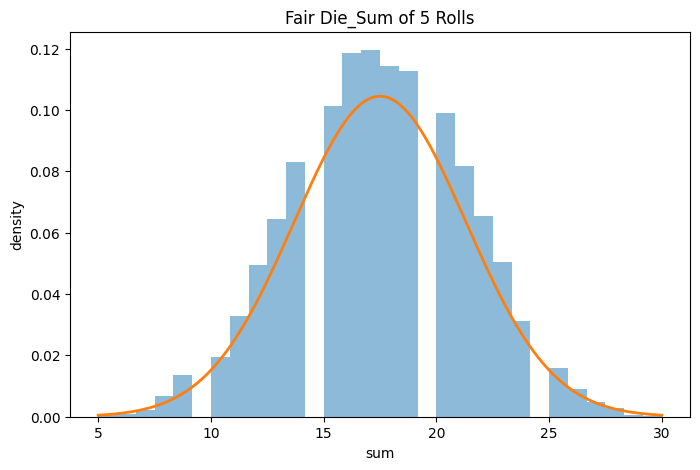

Simulated mean of the distribution of means of samples: 3.4826
Simulated of the distribution of means of samples: 2.9407


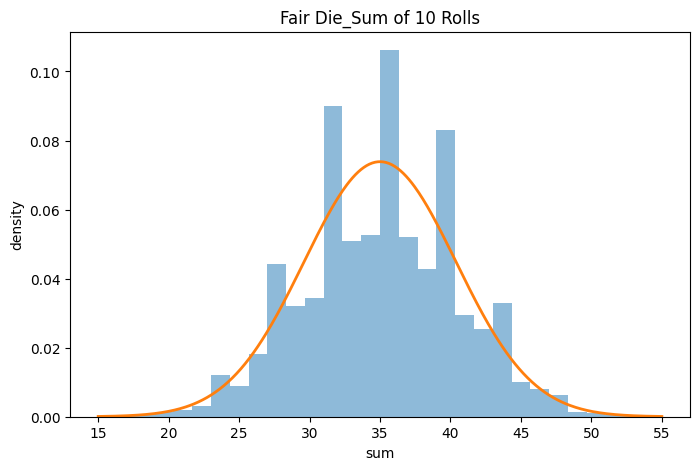

Simulated mean of the distribution of means of samples: 3.4944
Simulated of the distribution of means of samples: 2.9317


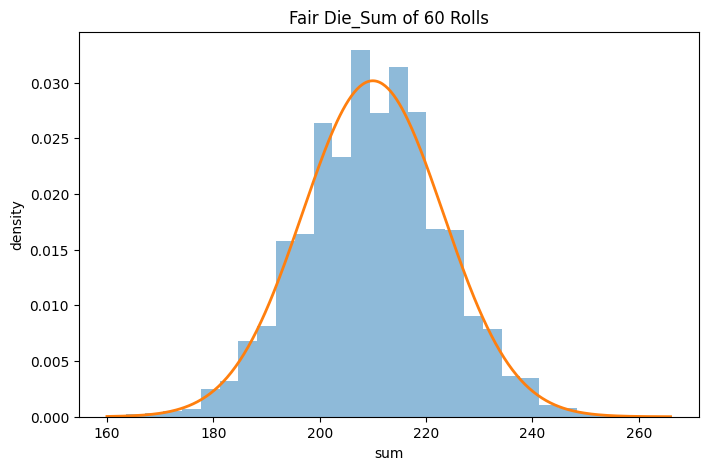

Simulated mean of the distribution of means of samples: 3.5000
Simulated of the distribution of means of samples: 2.9109


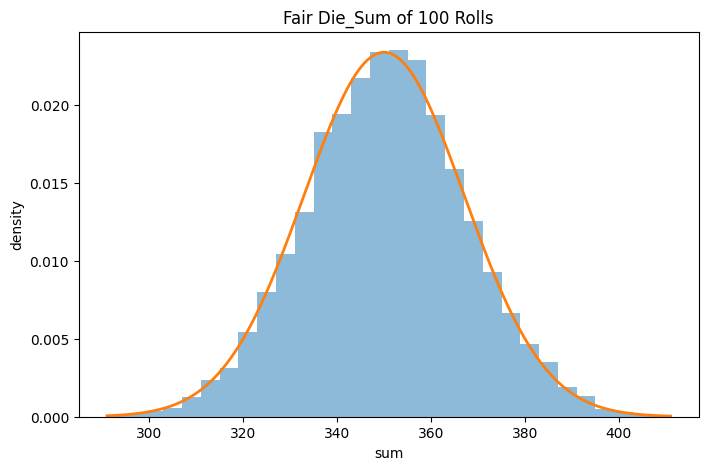

Simulated mean of the distribution of means of samples: 3.4997
Simulated of the distribution of means of samples: 2.9038


In [13]:
n_trials = 10000
roll_counts = [5, 10, 60, 100]

# ---------------------------------
# Fair die experiments
# ---------------------------------
for n in roll_counts:
    sums_fair = simulate_sums(roll_fair_die,n,n_trials)
    plot_with_normal(sums_fair,n,fair_mu,np.sqrt(fair_sigma2),"Fair Die_Sum of " + str(n) + " Rolls")
    # Here we print the mean and variance of the distribution of means of samples (Hence the division on n)
    print(f"Simulated mean of the distribution of means of samples: {np.mean(sums_fair)/n:.4f}")
    print(f"Simulated of the distribution of means of samples: {np.var(sums_fair)/n:.4f}")

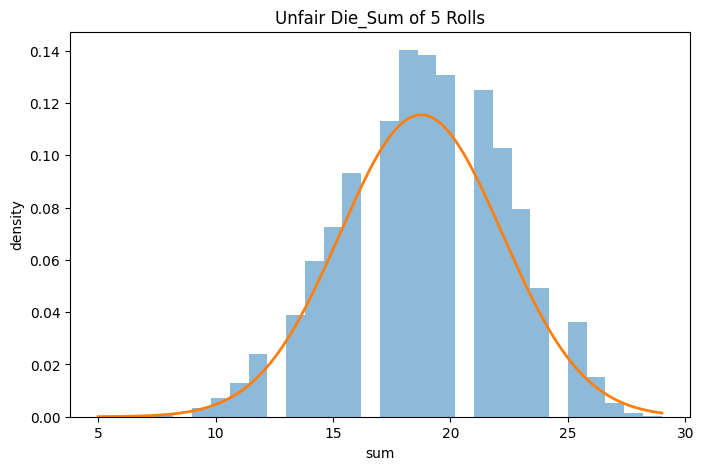

Simulated mean: 3.7646
Simulated variance: 2.4134


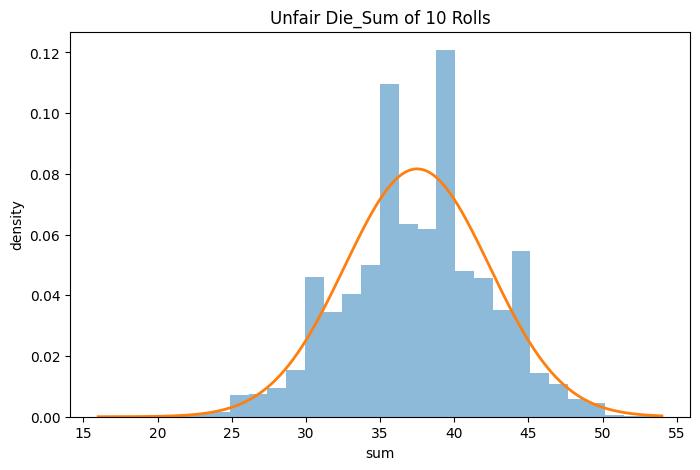

Simulated mean: 3.7525
Simulated variance: 2.3897


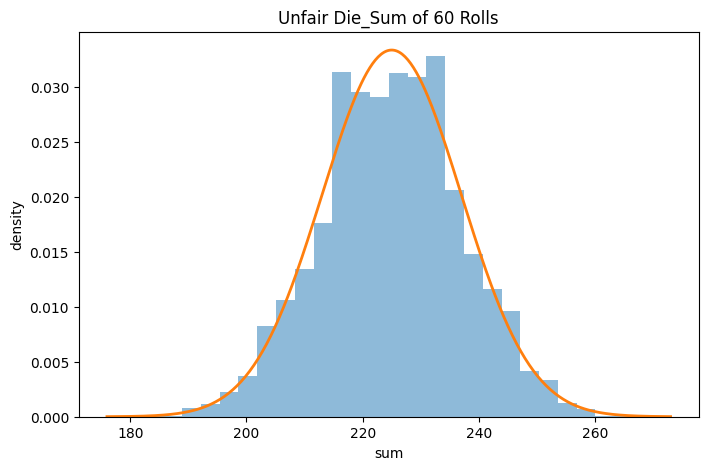

Simulated mean: 3.7501
Simulated variance: 2.4123


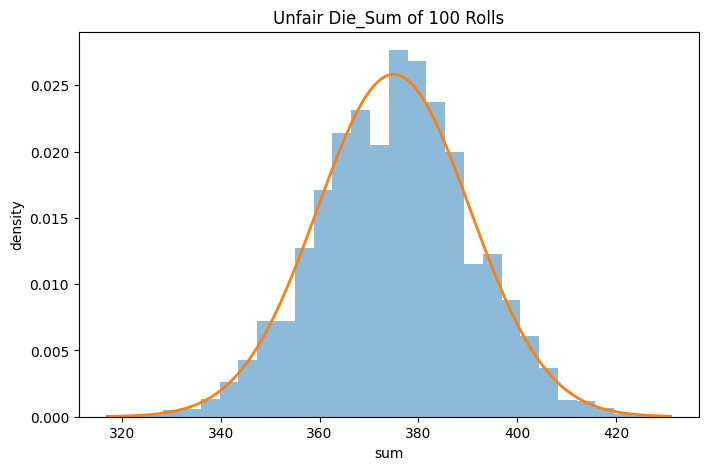

Simulated mean: 3.7517
Simulated variance: 2.3639


In [23]:
# ---------------------------------
# Unfair die experiments
# ---------------------------------
for n in roll_counts:
    sums_unfair = simulate_sums(roll_unfair_die,n,n_trials)
    plot_with_normal(sums_unfair,n,unfair_mu,np.sqrt(unfair_sigma2),"Unfair Die_Sum of " + str(n) + " Rolls")
    # Here we print the mean and variance of the distribution of means of samples (Hence the division on n)
    print(f"Simulated mean: {np.mean(sums_unfair)/n:.4f}")
    print(f"Simulated variance: {np.var(sums_unfair)/n:.4f}")

## Questions



*   What do you see in the histograms when the $n$ increases?

`[ANSWER]`:"همان طور دیده می شود، چه در حالت تاس سالم و چه ناسالم، هیستوگرام ها دارند شبیه به نمودار نرمال با واریانس nsigma2 و میانگین nmu می شوند"

*   How does the mean and variance of $\bar{X}_n = \frac{1}{n} \sum_{i=1}^n X_i$ evolve as $n$ is increased?

`[ANSWER]`:"میانگین همان مقدار میانگین هیستوگرام ما می ماند ولی واریانس آن با نسبت عکس با n، کاهش می یابد"
